In [10]:
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

In [7]:
DATAPATH = '../../data/output'
RESULTS = 'average_5_experiments_20211103-150900.csv'

# Configuration
EPISODES = 5000
EPS_DECAY = 0.9985
BUFFERSIZE = 500
MIN_EXP = 100
BATCH_SIZE = 50
UPDATE_THRESHOLD = 1000

In [8]:
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()

C:\Users\jmuir\miniconda3\envs\urban-mobility-simulation\lib\site-packages\ipykernel_launcher.py:19: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.


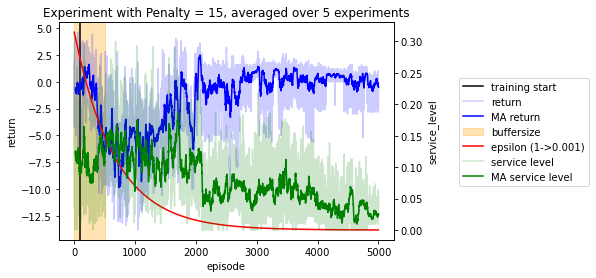

In [9]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, BUFFERSIZE, color='orange', alpha=.3, label='buffersize')
plt.axvline(MIN_EXP, color='black', label='training start')
x_ = np.linspace(1,EPISODES)
ax_ = plt.twinx(ax)
sns.lineplot(x=x_, y=EPS_DECAY**x_, color='red', ax=ax_, label='epsilon (1->0.001)', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
ax2 = ax.twinx()
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

plt.title('Experiment with Penalty = 15, averaged over 5 experiments')
fig.patch.set_facecolor('white')
fig.legend(bbox_to_anchor=(1.04,0.5), loc="center left")
fig.show()

In [11]:
BENCHMARK = '5000_episodes_benchmark_20211105-151122.csv'

<AxesSubplot:xlabel='episode', ylabel='service_level'>

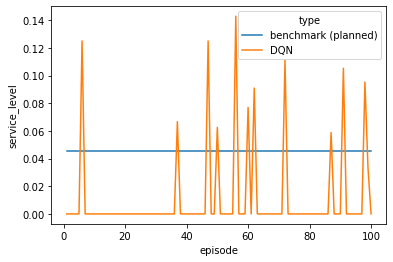

In [15]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK))
sns.lineplot(data=benchmark_results, x='episode', y='service_level', hue='type')